# Does category structure increase along the layers mapped to V1, V2, V4 and IT?

| | |
| --- | --- |
| **Question** | In a ResNet-50 whose stages are mapped to V1, V2, V4 and IT, does the separation of image categories increase from the V1 layer to the IT layer, and does this depend on training? |
| **Requires** | CPU only. ImageNet ResNet-50 weights from torchvision (about 100 MB, downloaded on first run, then cached). No neural data. About 1 minute. |
| **Lessons used** | [3. Wrap a PyTorch model](../lessons/03_wrap_a_pytorch_model.ipynb), [5. Layers and regions](../lessons/05_layers_and_regions.ipynb) |

## Background

In the primate ventral stream, responses in IT separate object categories more clearly
than responses in V1 do. Deep convolutional networks trained on object recognition show a
similar progression across their stages, which is one reason their stages are commonly
mapped to visual areas. Before a layer-to-region mapping is tested against neural data, it
is useful to check that the mapped layers show the expected ordering on simple inputs, and
that the ordering comes from training rather than from the architecture alone.

The region names in this notebook are proposed mappings for model layers. No brain data
are used. Scoring a layer against recorded IT responses is shown in
[experiment 03](03_predicting_it_responses.ipynb).

## Hypothesis

In the trained network, the ratio of between-category to within-category dissimilarity
increases from the layer mapped to V1 to the layer mapped to IT. In the same architecture
with random weights, the increase is smaller.

## Method

The stimuli are 24 synthetic images in four visually distinct categories (six per
category). The next cell renders them and builds a `StimulusSet`. The `image_file_name`
column is required: it tells the subject that the stimuli are images.

In [1]:
%matplotlib inline
import os
import tempfile
import numpy as np
import pandas as pd
from PIL import Image
from brainscore_core.supported_data_standards.brainio.stimuli import StimulusSet

CATEGORIES = ['warm-stripes', 'cool-stripes', 'green-blobs', 'gray-noise']
N_PER_CATEGORY = 6

def make_image(category, k):
    """Render one seeded 224x224 RGB image from the given category."""
    r = np.random.RandomState(CATEGORIES.index(category) * 100 + k)
    x = np.zeros((224, 224, 3), np.float32)
    yy, xx = np.mgrid[0:224, 0:224]
    if category == 'warm-stripes':
        s = (np.sin(xx / (6 + r.rand() * 4)) + 1) / 2
        x[..., 0] = 200 * s + 40
        x[..., 1] = 90 * s + 20
    elif category == 'cool-stripes':
        s = (np.sin(yy / (6 + r.rand() * 4)) + 1) / 2
        x[..., 2] = 200 * s + 40
        x[..., 1] = 80 * s + 20
    elif category == 'green-blobs':
        for _ in range(25):
            cy, cx = r.randint(20, 204, 2)
            rad = r.randint(8, 20)
            mask = ((yy - cy) ** 2 + (xx - cx) ** 2) < rad ** 2
            x[mask, 1] += 150
            x[mask, 0] += 40
    else:
        noise = np.kron(r.rand(56, 56, 1), np.ones((4, 4, 1)))
        x[:] = 80 + 120 * noise
    x += r.randn(224, 224, 3) * 6
    return np.clip(x, 0, 255).astype(np.uint8)

folder = tempfile.mkdtemp(prefix='layer_region_')
rows = []
for category in CATEGORIES:
    for k in range(N_PER_CATEGORY):
        stimulus_id = f'{category}_{k}'
        path = os.path.join(folder, f'{stimulus_id}.png')
        Image.fromarray(make_image(category, k)).save(path)
        rows.append({'stimulus_id': stimulus_id, 'image_file_name': path, 'category': category})

stimuli = StimulusSet(pd.DataFrame(rows))
stimuli.identifier = 'layer-region-synthetic'
stimuli.stimulus_paths = {row['stimulus_id']: row['image_file_name'] for row in rows}
categories = np.asarray(stimuli['category'].values)
print(f'{len(stimuli)} stimuli in {len(CATEGORIES)} categories')

24 stimuli in 4 categories


Four example images per category:

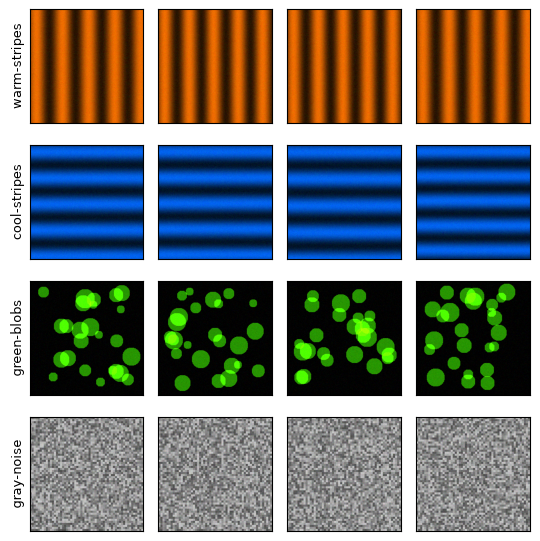

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(CATEGORIES), 4, figsize=(5.5, 5.6))
for ci, category in enumerate(CATEGORIES):
    for k in range(4):
        ax = axes[ci, k]
        ax.imshow(make_image(category, k))
        ax.set_xticks([])
        ax.set_yticks([])
        if k == 0:
            ax.set_ylabel(category, fontsize=9)
fig.tight_layout()
plt.show()

The next cell wraps a ResNet-50 as a subject. The `region_layer_map` assigns each of
the four residual stages to one region. The same function builds the trained network
(ImageNet weights) and the untrained control (random weights, fixed seed).

In [3]:
import torch
import torchvision.models as tvm
from brainscore_core.model_interface import BrainScoreModel
from brainscore_vision.model_helpers.activations.pytorch import load_preprocess_images
from brainscore.model_helpers.vision_wrapper import VisionWrapper

REGION_LAYER_MAP = {'V1': 'layer1', 'V2': 'layer2', 'V4': 'layer3', 'IT': 'layer4'}
REGIONS = list(REGION_LAYER_MAP)

def make_subject(trained):
    torch.manual_seed(0)
    weights = tvm.ResNet50_Weights.IMAGENET1K_V2 if trained else None
    network = tvm.resnet50(weights=weights).eval()
    identifier = 'resnet50-imagenet' if trained else 'resnet50-random'
    extractor = VisionWrapper(
        identifier=identifier, model=network,
        preprocessing=lambda paths: load_preprocess_images(paths, image_size=224))
    return BrainScoreModel(identifier=identifier, model=network,
                           region_layer_map=REGION_LAYER_MAP,
                           extractor={'vision': extractor})

The next cell records all four regions in one session. The session asks the subject
for one neural response per region, and `session.collect('neural:<region>')` returns that
region's assembly (rows are images, columns are units).

In [4]:
from brainscore_core.streaming_helpers import stimulus_session

def record_regions(subject):
    session = stimulus_session(stimuli, record=REGIONS)
    subject.participate(session)
    return {region: np.asarray(session.collect(f'neural:{region}').values)
            for region in REGIONS}

features = {'trained': record_regions(make_subject(trained=True)),
            'random': record_regions(make_subject(trained=False))}
for region in REGIONS:
    print(region, features['trained'][region].shape)

activations:   0%|          | 0/64 [00:00<?, ?it/s]

layer packaging:   0%|          | 0/4 [00:00<?, ?it/s]

activations:   0%|          | 0/64 [00:00<?, ?it/s]

layer packaging:   0%|          | 0/4 [00:00<?, ?it/s]

V1 (24, 802816)
V2 (24, 401408)
V4 (24, 200704)
IT (24, 100352)


A representational dissimilarity matrix (RDM) holds `1 - correlation` between the
responses to every pair of images. The separation ratio is the mean between-category
dissimilarity divided by the mean within-category dissimilarity. A ratio of 1 means the
two averages are equal; larger values mean the categories are further apart.

In [5]:
def rdm(responses):
    centered = responses - responses.mean(axis=1, keepdims=True)
    centered /= np.linalg.norm(centered, axis=1, keepdims=True) + 1e-8
    return 1 - centered @ centered.T

same = categories[:, None] == categories[None, :]
off_diagonal = ~np.eye(len(categories), dtype=bool)

def separation_ratio(responses):
    d = rdm(responses)
    return d[~same].mean() / d[same & off_diagonal].mean()

ratios = {name: [separation_ratio(features[name][r]) for r in REGIONS] for name in features}

## Results

RDMs for the four mapped regions of the trained network, ordered by category:

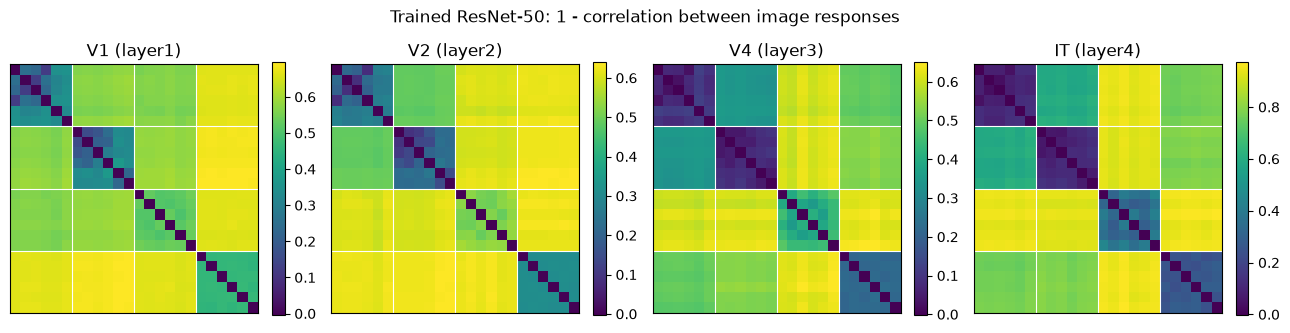

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, region in zip(axes, REGIONS):
    im = ax.imshow(rdm(features['trained'][region]), cmap='viridis')
    ax.set_title(f'{region} ({REGION_LAYER_MAP[region]})')
    ax.set_xticks([])
    ax.set_yticks([])
    for b in (6, 12, 18):
        ax.axhline(b - 0.5, c='w', lw=0.8)
        ax.axvline(b - 0.5, c='w', lw=0.8)
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle('Trained ResNet-50: 1 - correlation between image responses')
fig.tight_layout()
plt.show()

Dark blocks on the diagonal are pairs of images from the same category. The blocks
are clearer in the IT layer than in the V1 layer.

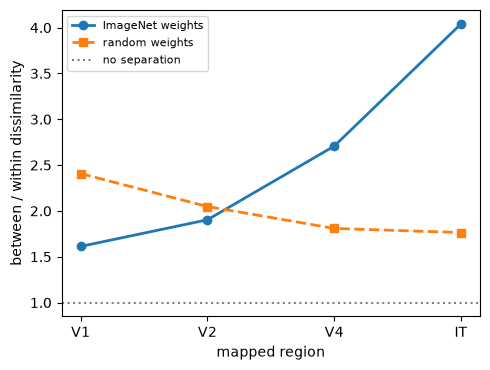

trained {'V1': 1.61, 'V2': 1.9, 'V4': 2.71, 'IT': 4.04}
random {'V1': 2.41, 'V2': 2.05, 'V4': 1.81, 'IT': 1.76}


In [7]:
fig, ax = plt.subplots(figsize=(5, 3.8))
ax.plot(REGIONS, ratios['trained'], 'o-', lw=2, label='ImageNet weights')
ax.plot(REGIONS, ratios['random'], 's--', lw=2, label='random weights')
ax.axhline(1, ls=':', c='gray', label='no separation')
ax.set_ylabel('between / within dissimilarity')
ax.set_xlabel('mapped region')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
for name in ratios:
    print(name, {r: round(v, 2) for r, v in zip(REGIONS, ratios[name])})

In the trained network the separation ratio rises monotonically from 1.61 (V1 layer)
to 4.04 (IT layer). In the random-weight network it falls from 2.41 to 1.76, and its V1
layer separates the categories more than the trained V1 layer does.

A cross-validated linear classifier gives a second measure. On four visually distinct
categories it can reach perfect accuracy at every layer, so it may not distinguish the
layers even when the RDMs differ.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

for region in ['V1', 'IT']:
    accuracy = cross_val_score(LogisticRegression(max_iter=2000),
                               features['trained'][region], categories, cv=3).mean()
    print(f'trained {region}: decoding accuracy {accuracy:.2f}')

trained V1: decoding accuracy 1.00


trained IT: decoding accuracy 1.00


Both layers decode the four categories perfectly, so decoding accuracy does not
distinguish them here.

## Conclusion and limits

On these stimuli, the separation ratio of the trained ResNet-50 rises from the layer
mapped to V1 to the layer mapped to IT, while the same architecture with random weights
shows a decrease. The increase along the mapped layers therefore depends on training and
not on the architecture alone. This is a consistency check on the proposed mapping, not
evidence that the mapping is correct. The random control uses a single seed.

The images are four synthetic texture categories, not objects, and there are only 24 of
them. Separation ratios are not comparable with neural predictivity scores. To decide
which layer best matches a brain region, each candidate layer must be scored against
recordings from that region with a benchmark, as in
[experiment 03](03_predicting_it_responses.ipynb).

[Lessons](../lessons/) · [Documentation](../../docs/README.md)